## Tutorial: modelling dispersion on a DNA-inspired $\pi$-stacking system with BEAST-VQE 

In this tutorial notebook, we will run an adaptive variational algorithm (BEAST-VQE) to estimate the energy of a $\pi$-stacked system along a scan of the distance between the stacked fragments, from the equilibrium geometry to the dissociated limit. The quantum chemistry problem is built with projective embedding, and the quantum algorithm is simulated with Kvantify's memory-restricted simulator.

<div align="center"><img src="images/pi_stacking_image.png" alt="Thymine dimer extracted from the DNA atomistic model PDB 208D" width="450"></div>

All of the classes and methods we need will be found in the `qrunch` package. The documentation for the Kvantify Qrunch can be found [here](https://qrunch.docs.kvantify.net/index.html). We also define the folders where files will be stored, and set up the logger, which allows us to keep track of basic information when running the algorithms.

In [1]:
import dataclasses
import json
import logging
from pathlib import Path

import matplotlib.pyplot as plt
import qrunch as qc
from qrunch.common.execution_timer import TimerContext, get_execution_timings

result_path = Path("results")
result_path.mkdir(exist_ok=True, parents=True)

output_path = Path("output")
output_path.mkdir(exist_ok=True, parents=True)

qc.setup_logger(logging.INFO)

/var/folders/nv/wdtx9y4n5rl1f5ffmpclqfj80000gn/T/ipykernel_36487/3067496315.py:8: UserWarning: The module 'qrunch.common.execution_timer' is not part of the public API of 'qrunch'. Its interface may change without notice.
The module was imported from __main__.
  from qrunch.common.execution_timer import TimerContext, get_execution_timings


## Hardware requirements
The memory-restricted simulator keeps only a limited number of amplitudes of the state vector, so the memory needed by the quantum part of this tutorial is bounded and controlled by a single parameter (see below). The embedding and active space step is much more demanding, but in this notebook the persister files related to mean-field, MP2 and active space data are provided in order to keep the execution time low. They are found in `output/persister_data`.

### Setting up the experiment

The starting point is an .xyz file containing the 17 points of the scan. We generate a `Path` instance from it, which is an accepted input for our builders. We also collect here the key parameters of the calculation, so that they are easy to modify later if you want to test different settings. THe system is neutral and in the singlet spin state. We include in the embedded region most of the atoms while excluding the alkyl groups. For the sake of time, only 6 out of the 17 geometries are used for the VQE runs.

In [20]:
reaction_path = Path("submodel_dt6dt7_scan.xyz")

bset = "6-31+g"
embedded_atoms = [2, 3, 4, 5, 6, 7, 8, 10, 12, 13, 14, 15, 16, 17, 18, 20, 24, 25, 27, 28]
charge = 0
spin = 0

# (16 spatial orbitals, 10 electrons) active space, i.e. 32 qubits.
active_orbitals = 16
active_alpha_electrons = 5

shots = 1000
iterations = 20

# Geometries (0-based, out of the 17 scan points) for the VQE; index 2 is the minimum, 16 the dissociated limit.
selected_geometries = [0, 1, 2, 4, 6, 9, 16]

result_name = "pi_stacking_mr_16o.json"

Now we build our reaction configuration. In all frames of the scan, we rely on [projective embedding theory](https://qrunch.docs.kvantify.net/docs/explanations/projective_embedding.html) to describe the system: the environment is handled through a DFT mean-field model, while the embedded atoms are treated explicitly with a correlated wave function method, in this case BEAST-VQE as we will discuss later. We pass the basis set (here `6-31+g`), the total charge, the spin difference (number of alpha minus beta electrons) and the list of atoms forming the embedded region.
We define our reaction configuration object including all the information required as it will be used later for building the so called problem.

In [21]:
reaction_config = qc.build_reaction_configuration(
    reaction=reaction_path,
    basis_set=bset,
    charge=charge,
    spin_difference=spin,
    embedded_atoms=embedded_atoms,
)

### Creating the problem with the problem builder

We use the [fluent build pattern](https://qrunch.docs.kvantify.net/docs/explanations/builder_pattern.html) to construct a `problem_builder_creator`. As in the dehalogenase tutorial, we calculate along a `reaction_path` with the `even_handed` approach, so that the active orbital assignment is consistent across all frames of the scan. This is crucial for a smooth potential energy surface.

The choices below are:
- a DFT (B3LYP) full-system mean-field calculation;
- an orbital assignment based on the total weight of the atomic orbital contributions;
- MP2 natural orbitals for the embedded region (with a truncation of the virtual space);
- resolution of the identity for the two-electron repulsion integrals;
- an active space modifier, selecting 16 spatial orbitals and 5 alpha electrons, followed by a conversion to dense integrals.

**Important:** to reuse the orbitals and MP2 calculations that were already performed, every option that determines the stored data (functional, basis set, assignment tolerance, MP2 threshold, auxiliary basis, active space, ...) must be identical to the ones used in the earlier run.

Note that some of the options reported here could have been skipped as they are given as default ones by qrunch, however, we report them to give the user a broader overview in case she/he was tempted to test different settings.

In [22]:
dft_options = qc.options.DftCalculatorOptions(functional="b3lyp")
mp2_options = qc.options.MollerPlesset2CalculatorOptions(virtual_truncation_threshold=1e-6)

persister_path = output_path / "persister_data"
persister_path.mkdir(exist_ok=True, parents=True)

reaction_builder_creator = (
    qc.problem_builder_creator()
    .reaction_path()
    .even_handed()
    .choose_full_system_solver()
    .dft(dft_options)
    .choose_orbital_assigner()
    .total_weight(assignment_tolerance=0.3)
    .choose_embedded_orbital_calculator()
    .moller_plesset_2(mp2_options)
    .choose_repulsion_integral_builder()
    .resolution_of_the_identity(auxiliary_basis="heavy-aug-cc-pvdz-ri")
    .add_problem_modifier()
    .active_space(active_orbitals, active_alpha_electrons)
    .add_problem_modifier()
    .to_dense_integrals()
)

When running calculations on embedded systems, it is useful to store the mean-field results and orbital assignment details so that they can be reused. This is the role of the `data_persister_manager`. We point it to the existing `persister_data` folder, and use `load_policy="fallback"`: the stored files are loaded when present, and generated only if they are missing.

In [23]:
reaction_builder_creator = (
    reaction_builder_creator.choose_data_persister_manager().file_persister(
        directory=persister_path,
        extension=".qdk",
        load_policy="fallback",
        overwriting_policy="overwrite",
    )
)

reaction_builder = reaction_builder_creator.create()

We now build the even-handed reaction path problem. Since the persisted files are already in place, this step should only load them (check the log: it should not start new DFT or MP2 calculations). The full scan is built, so that the even-handed active spaces stay consistent, and then we keep only the geometries selected for the VQE runs.

In [24]:
with TimerContext("Problem build (embedding & active space)"):
    full_reaction_problem = reaction_builder.build_restricted(reaction_config)

reaction_problem = dataclasses.replace(
    full_reaction_problem,
    ground_state_problems=[full_reaction_problem.ground_state_problems[i] for i in selected_geometries],
)
print(f"Running VQE on geometries {selected_geometries} out of {len(full_reaction_problem.ground_state_problems)}")

2026-11-03 15:49:56 [INFO] (kvantify.qrunch): Embedded atoms: [
    N: (9.359, 20.621, 2.68),
    C: (8.607, 19.479, 2.529),
    O: (7.436, 19.482, 2.212),
    N: (9.207, 18.286, 2.75),
    C: (10.496, 18.116, 3.111),
    O: (10.914, 16.977, 3.256),
    C: (11.24, 19.351, 3.252),
    C: (10.662, 20.544, 3.038),
    N: (5.82, 20.104, 5.63),
    C: (5.875, 18.704, 5.589),
    O: (4.924, 18.004, 5.282),
    N: (7.065, 18.102, 5.901),
    C: (8.223, 18.748, 6.252),
    O: (9.251, 18.092, 6.395),
    C: (8.112, 20.206, 6.301),
    C: (6.933, 20.839, 5.991),
    H: (8.644, 17.45535, 2.63535),
    H: (11.24096, 21.4485, 3.15236),
    H: (7.0923, 17.09285, 5.86987),
    H: (6.87564, 21.91678, 6.02962),
]
2026-11-03 15:49:56 [INFO] (kvantify.qrunch): Embedded atoms: [
    N: (9.359, 20.621, 2.68),
    C: (8.607, 19.479, 2.529),
    O: (7.436, 19.482, 2.212),
    N: (9.207, 18.286, 2.75),
    C: (10.496, 18.116, 3.111),
    O: (10.914, 16.977, 3.256),
    C: (11.24, 19.351, 3.252),
    C: (10.66

Running VQE on geometries [0, 1, 2, 4, 6, 9, 16] out of 17


### Running the quantum algorithm

Now we define the `estimator` and the `sampler`. The `estimator` computes expectation values (for instance of the Hamiltonian), while the `sampler` returns samples from the state and is used for gate selection.

In this tutorial both are based on the `memory_restricted` simulator. It prunes the state vector simulation according to memory criteria, keeping only the most relevant amplitudes. With `with_precise_defaults` it keeps at most 1,000,000 amplitudes and raises a warning if the simulation cannot be done accurately enough.

The estimator is created as:

In [25]:
estimator = qc.estimator_creator().memory_restricted().with_precise_defaults().create()

while the sampler follows the same pattern:

In [26]:
sampler = qc.sampler_creator().memory_restricted().with_precise_defaults().create()


Next we set the options for the adaptive VQE. We add one gate per iteration, and we force all iterations to run independently of convergence, so that all geometries are treated with the same computational effort.

In [27]:
adaptive_vqe_options = qc.options.IterativeVqeOptions(
    max_iterations=iterations,
    gates_per_iteration=1,
    force_all_iterations=True,
)

With those elements, we can set up the VQE calculator using a `calculator_creator`. We choose an iterative VQE with orbital optimization, using the BEAST-VQE algorithm. The sampler is used for gate selection (with a finite number of shots), and the estimator is used for the energy evaluations, for the second-order perturbation theory (PT2) corrector and for the orbital optimizer. In fact, BEAST's gate pool only allows for paired electron excitations and the broken pairs excitations are included via this PT2 correction at the very last part of the VQE run once all iterations are completed. The intermittent orbital optimizer uses the `quick` preset.

In [28]:
calculator = (
    qc.calculator_creator()
    .vqe()
    .iterative_with_orbital_optimization()
    .beast()
    .with_gate_selector_sampler(sampler)
    .with_gate_selector_shots(shots)
    .with_estimator(estimator)
    .with_options(adaptive_vqe_options)
    .with_second_order_corrector(estimator)
    .with_orbital_optimizer_estimator(estimator)
    .with_intermittent_orbital_optimizer_options(qc.options.IntermittentOrbitalOptimizerAlgorithmOptions.quick())
    .create()
)

Now the chemistry definitions and the quantum algorithm come together. We run the calculator on our reaction problem; it performs the orbital optimized and perturbation theory corrected BEAST-VQE for each of the selected geometries. The `result` object will contain the information on energies and convergence behaviour.

In [29]:
with TimerContext("BEAST VQE"):
    result = calculator.calculate(reaction_problem)

print(qc.get_execution_times_report())

2026-11-03 15:50:09 [INFO] (kvantify.qrunch): Run Adaptive Orbital Optimization VQE algorithm with 16 qubits:


2026-11-03 15:50:09 [INFO] (kvantify.qrunch): Gate pool with 55 gates registered.
2026-11-03 15:50:09 [INFO] (kvantify.qrunch): The memory restricted simulation used a maximum of 1/1000000 amplitudes, and the state vector simulation was exact.
2026-11-03 15:50:09 [INFO] (kvantify.qrunch): Initial orbital optimization gradient norm: 9.10987143218138e-05
2026-11-03 15:50:09 [INFO] (kvantify.qrunch): Running Adaptive VQE iteration: 1 / 20
2026-11-03 15:50:09 [INFO] (kvantify.qrunch): The memory restricted simulation used a maximum of 1/1000000 amplitudes, and the state vector simulation was exact.
2026-11-03 15:50:09 [INFO] (kvantify.qrunch): Running basic VQE
2026-11-03 15:50:09 [INFO] (kvantify.qrunch): FFT Newton refinement converged in 1 iterations. 
2026-11-03 15:50:09 [INFO] (kvantify.qrunch): Optimal parameters found: [0.0685789]
2026-11-03 15:50:09 [INFO] (kvantify.qrunch): Minimized function value found: -12.107524043468748
2026-11-03 15:50:09 [INFO] (kvantify.qrunch): Gate Addit


Total calculation time: 24.8577 s.

Problem build (embedding & active space): 3.0090 s (12.10%)
..  OrbitalAssigner.assign: 0.9950 s (4.00%)
BEAST VQE: 21.8488 s (87.90%)
..  BeastVqeGroundStateCalculator.calculate: 20.0177 s (80.53%)
..  ..  JordanWignerMapper.map: 0.0145 s (0.06%)
..  ..  ReducedDensityMatrixCalculator.calculate: 0.0760 s (0.31%)
..  ..  ..  Estimator.run: 0.0641 s (0.26%)
..  ..  OrbitalOptimizationVqe.iteration: 19.8448 s (79.83%)
..  ..  ..  GateSelector.select_gates: 0.1696 s (0.68%)
..  ..  ..  ..  Sampler.run: 0.1168 s (0.47%)
..  ..  ..  ..  calculating importance metrics u64: 0.0422 s (0.17%)
..  ..  ..  BasicVqeAlgorithm.run: 9.8146 s (39.48%)
..  ..  ..  ..  Estimator.run: 6.5376 s (26.30%)
..  ..  ..  ReducedDensityMatrixCalculator.calculate: 0.5556 s (2.24%)
..  ..  ..  ..  Estimator.run: 0.3964 s (1.59%)
..  ..  ..  rotating operators: 1.4966 s (6.02%)
..  ..  ..  GradientCalculator.compute_gradient: 2.0288 s (8.16%)
..  ..  ..  ..  ReducedDensityMatrix

### Extracting results

We can now look at the energies found across the selected geometries, and then check how the algorithm converges for two representative points of the scan. First, the final total energy for each geometry:

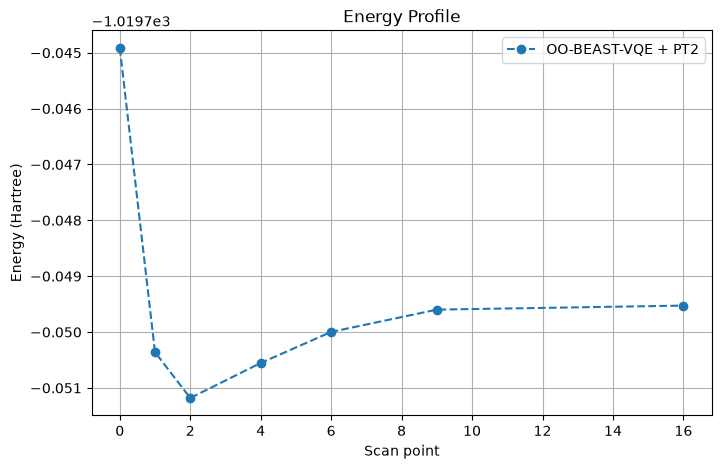

In [31]:
final_reaction_energies = result.total_energies.values

plt.figure(figsize=(8, 5))
plt.plot(selected_geometries, final_reaction_energies, marker="o", linestyle="--", label="OO-BEAST-VQE + PT2")
plt.xlabel("Scan point")
plt.ylabel("Energy (Hartree)")
plt.title("Energy Profile")
plt.legend()
plt.grid()
plt.show()

Have we found convergence for the energy? We can check that by looking at how the electronic energy evolves with the number of iterations. We focus on two geometries: scan point 2, the minimum of the energy profile, and scan point 16, the fully dissociated dimer. These are the two extremes of the interaction, with the stacked fragments at their equilibrium distance and effectively non-interacting. Since the two geometries have different total energies, each one is shown in its own panel with its own energy axis. Each point in a plot corresponds to a macro iteration of the algorithm (the first one being the initial energy and the last one the final energy). Note that the very last iteration corresponds to the addition of the PT2 correction.

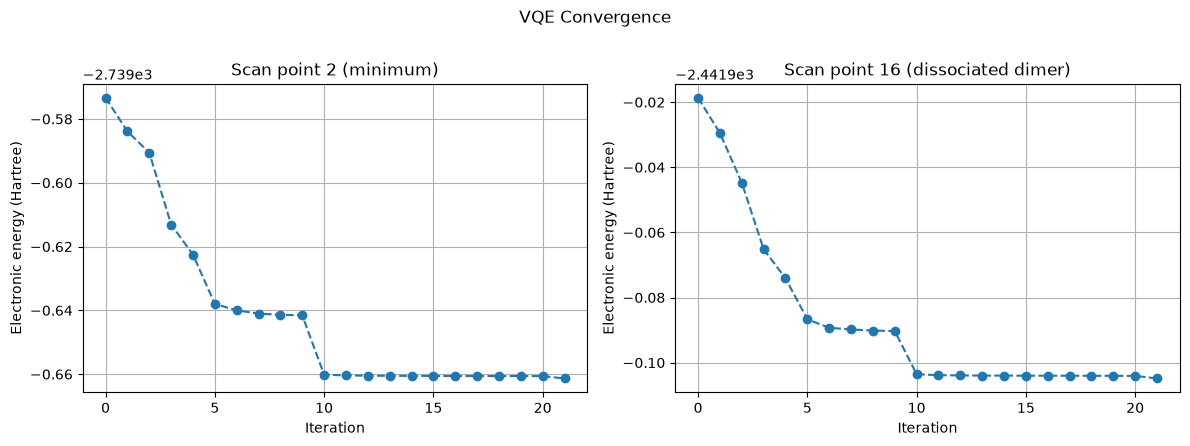

In [32]:
energy_per_iteration = [
    geometry_result.electronic_energy_per_macro_iteration_with_initial_energy_and_final_energy.values
    for geometry_result in result.ground_state_problem_results
]

convergence_points = {2: "minimum", 16: "dissociated dimer"}

fig, axes = plt.subplots(1, len(convergence_points), figsize=(12, 4.5))
for ax, (geometry_index, label) in zip(axes, convergence_points.items()):
    energies = energy_per_iteration[selected_geometries.index(geometry_index)]
    ax.plot(energies, marker="o", linestyle="--")
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Electronic energy (Hartree)")
    ax.set_title(f"Scan point {geometry_index} ({label})")
    ax.grid()
fig.suptitle("VQE Convergence")
fig.tight_layout()
plt.show()

Finally, we save the results, together with the main parameters of the calculation and the timings, to a JSON file.

In [19]:
final_data = {
    "charge": charge,
    "spin": spin,
    "basis_set": str(bset),
    "embedded_atom_indices": embedded_atoms,
    "cas": {
        "number_of_active_spatial_orbitals": active_orbitals,
        "number_of_active_alpha_electrons": active_alpha_electrons,
    },
    "simulator": "memory_restricted",
    "number_of_shots": shots,
    "number_of_iterations": iterations,
    "geometry_indices": selected_geometries,
    "timings_seconds": {" / ".join(k): round(v["time"], 2) for k, v in get_execution_timings().items()},
    "total_energy_per_geometry": [{"value": float(e), "error": 0.0} for e in final_reaction_energies],
    "nuclear_repulsion_per_geometry": [{"value": float(e), "error": 0.0} for e in result.nuclear_repulsions],
    "non_active_electrons_per_geometry": [
        {"value": float(e), "error": 0.0} for e in result.non_active_electrons_energies
    ],
    "electronic_energy_per_iteration_per_geometry": [
        [
            {"iteration": iteration_index, "value": float(energy), "error": 0.0}
            for iteration_index, energy in enumerate(energies)
        ]
        for energies in energy_per_iteration
    ],
}

with open(result_path / result_name, "w") as f:
    json.dump(final_data, f, indent=2)

print(f"Saved results to {result_path / result_name}")

Saved results to results/pi_stacking_mr_16o.json


### Now it's your turn

Some ideas to explore:
- change `max_number_of_amplitudes` of the memory-restricted simulator and check how the energies and the runtime change; how low should you go before observing energy discrepancies?
- run the VQE on the remaining scan points by editing `selected_geometries`;
